# ShipCarbon — Exploratory analysis of EU MRV ship CO₂ emissions

Public EU MRV data (EMSA THETIS-MRV), reporting years 2018–2025, cleaned by `pipeline/clean.py`.
This notebook reads only `data/processed/`, so it runs offline (no MongoDB needed).

**How totals are counted:** one row per ship per year (`ship_years.csv`). For 2024+ a ship's full report already
covers its partial reports, so partials are only used for ships without a full report (no double counting).

Charts are saved to `docs/img/`. Key insights are summarised in `docs/insights.md`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager
from matplotlib.patches import Patch

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed"
IMG = ROOT / "docs" / "img"
IMG.mkdir(parents=True, exist_ok=True)

# "Dusk at sea" palette. Amber = CO2 data; sea-glass = the comparison series; DIM = de-emphasised marks.
BG, LINE = "#0a1220", "#20324a"
TEXT, MUTED = "#e9eef4", "#9aabbf"
AMBER, SEAGLASS, DIM = "#ffb547", "#8fd0c8", "#4a5d78"

installed = {f.name for f in font_manager.fontManager.ttflist}
FONT = "IBM Plex Sans" if "IBM Plex Sans" in installed else "sans-serif"

plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "font.family": FONT, "font.size": 10.5,
    "text.color": TEXT, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": LINE, "axes.grid": True, "grid.color": LINE, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.axisbelow": True, "legend.frameon": False, "legend.labelcolor": TEXT,
    "xtick.major.size": 0, "ytick.major.size": 0, "figure.dpi": 100,
})


def titles(ax, title, subtitle):
    """Headline + muted subtitle above the (left-most) axes."""
    ax.annotate(title, (0, 1), xycoords="axes fraction", xytext=(0, 38), textcoords="offset points",
                fontsize=15, fontweight="bold", color=TEXT, ha="left", va="bottom")
    ax.annotate(subtitle, (0, 1), xycoords="axes fraction", xytext=(0, 16), textcoords="offset points",
                fontsize=10.5, color=MUTED, ha="left", va="bottom")


def save(fig, name):
    """Add the source line below everything else on the figure, then save the PNG."""
    fig.canvas.draw()
    box = fig.get_tightbbox(fig.canvas.get_renderer())  # in inches
    fig.text(box.x0 / fig.get_figwidth(), (box.y0 - 0.3) / fig.get_figheight(),
             "Source: EMSA THETIS-MRV (EU MRV), cleaned by ShipCarbon", color=MUTED, fontsize=8.5)
    fig.savefig(IMG / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()


print("Font:", FONT, "| images ->", IMG)

Font: sans-serif | images -> C:\Users\Hari\Desktop\shipcarbon\docs\img


In [2]:
read = dict(dtype={"imo": str}, keep_default_na=False, na_values=[""])
reports = pd.read_csv(DATA / "emissions.csv", **read)
ship_years = pd.read_csv(DATA / "ship_years.csv", **read)

# In 2025 EMSA relabelled most passenger ships as "Passenger ship (Cruise Passenger ship)". Merge the two labels
# so a ship type means the same thing in every year.
ship_years["ship_type"] = ship_years["ship_type"].replace(
    {"Passenger ship (Cruise Passenger ship)": "Passenger ship"})

# Sanity check: ship-year totals equal the report rows that count in totals.
assert np.isclose(ship_years["co2_t"].sum(), reports.loc[reports["counts_in_total"], "co2_t"].sum())

LATEST = int(ship_years["year"].max())
latest = ship_years[ship_years["year"] == LATEST]
ship_years.groupby("year").agg(ships=("imo", "size"), co2_Mt=("co2_t", lambda s: s.sum() / 1e6)).round(2).T

year,2018,2019,2020,2021,2022,2023,2024,2025
ships,12260.00,12420.00,12118.0,12485.00,13474.00,12829.00,14466.00,17842.00
co2_Mt,145.37,147.26,129.7,126.79,137.52,128.61,148.25,152.47


## Q1 · How has total CO₂ changed from 2018 to 2025?
The 2025 bar is split: ships that were *newly covered* in 2025 (general cargo and offshore ships seen for the first
time, the types added by the scope extension) are shown separately.

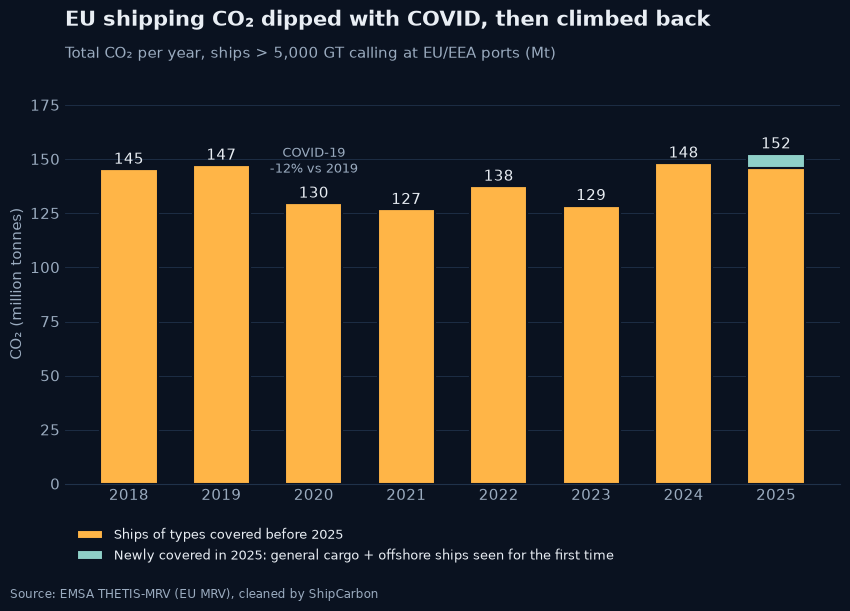

2020 vs 2019: -11.9%
2025 vs 2024: +4.22 Mt; newly covered ships: 6.65 Mt (2,185 ships)
Same 12,061 ships in both years: 134.6 -> 126.1 Mt (-6.3%)
Ships seen for the first time, per year: {2019: 2883, 2020: 1671, 2021: 1551, 2022: 1541, 2023: 1157, 2024: 1501, 2025: 3600}


In [3]:
first_year = ship_years.groupby("imo")["year"].transform("min")
NEW_SCOPE_TYPES = ["General cargo ship", "Other ship types (Offshore)"]
newly_covered = (ship_years["year"] == 2025) & (first_year == 2025) & ship_years["ship_type"].isin(NEW_SCOPE_TYPES)

by_year = ship_years.groupby("year")["co2_t"].sum() / 1e6
new_scope = ship_years[newly_covered].groupby("year")["co2_t"].sum().reindex(by_year.index, fill_value=0) / 1e6
before = by_year - new_scope

fig, ax = plt.subplots(figsize=(10, 5.2))
labels = by_year.index.astype(str)
ax.bar(labels, before, color=AMBER, width=0.62, edgecolor=BG, linewidth=1.5, label="Ships of types covered before 2025")
ax.bar(labels, new_scope, bottom=before, color=SEAGLASS, width=0.62, edgecolor=BG, linewidth=1.5,
       label="Newly covered in 2025: general cargo + offshore ships seen for the first time")
for x, v in zip(labels, by_year):
    ax.annotate(f"{v:.0f}", (x, v), xytext=(0, 4), textcoords="offset points", ha="center", color=TEXT)
covid = (by_year[2020] / by_year[2019] - 1) * 100
ax.annotate(f"COVID-19\n{covid:.0f}% vs 2019", ("2020", by_year[2020]), xytext=(0, 22), textcoords="offset points",
            ha="center", color=MUTED, fontsize=9.5)
ax.set_ylim(0, 185)
ax.set_ylabel("CO₂ (million tonnes)")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.08), ncol=1, fontsize=9.5)
titles(ax, "EU shipping CO₂ dipped with COVID, then climbed back",
       "Total CO₂ per year, ships > 5,000 GT calling at EU/EEA ports (Mt)")
save(fig, "01_co2_per_year")

both = set(ship_years.query("year == 2024")["imo"]) & set(ship_years.query("year == 2025")["imo"])
same = ship_years[ship_years["imo"].isin(both)].groupby("year")["co2_t"].sum().loc[[2024, 2025]] / 1e6
print(f"2020 vs 2019: {covid:.1f}%")
print(f"2025 vs 2024: {by_year[2025] - by_year[2024]:+.2f} Mt; newly covered ships: {new_scope[2025]:.2f} Mt "
      f"({newly_covered.sum():,} ships)")
print(f"Same {len(both):,} ships in both years: {same[2024]:.1f} -> {same[2025]:.1f} Mt "
      f"({(same[2025] / same[2024] - 1) * 100:.1f}%)")
new_per_year = ship_years[ship_years["year"] == first_year].groupby("year").size()
print("Ships seen for the first time, per year:", new_per_year.loc[2019:].to_dict())

**Answer.** CO₂ fell about 12% in 2020 (147 → 130 Mt) and only passed the 2019 level again in 2024. The 2025 rise
(+4.2 Mt) is a scope effect: newly covered general cargo and offshore ships add about 6.6 Mt, while the ~12,000 ships
reported in both 2024 and 2025 emitted about 6% *less* — so compare 2025 with earlier years carefully.

## Q2 · Which ship types emit the most — in total and per ship?
Two panels with their own axes (not a dual axis): total CO₂ on the left, average CO₂ per ship on the right.

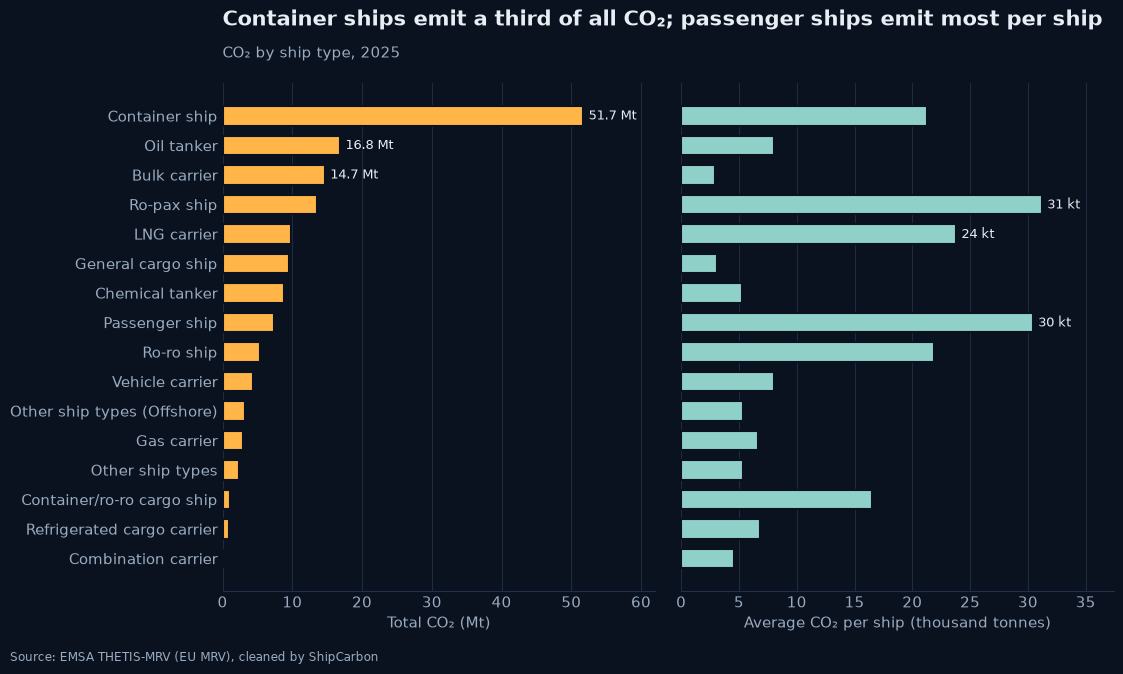

,ships,total_Mt,per_ship_kt,ship_share_%,co2_share_%
ship_type,,,,,
Container ship,2430,51.7,21.3,13.6,33.9
Oil tanker,2089,16.8,8.1,11.7,11.0
Bulk carrier,5013,14.7,2.9,28.1,9.6
Ro-pax ship,436,13.6,31.2,2.4,8.9
LNG carrier,414,9.8,23.8,2.3,6.5
General cargo ship,3092,9.5,3.1,17.3,6.2
Chemical tanker,1667,8.8,5.3,9.3,5.8
Passenger ship,244,7.4,30.4,1.4,4.9
Ro-ro ship,245,5.4,21.9,1.4,3.5


In [4]:
types = latest.groupby("ship_type").agg(
    ships=("imo", "size"),
    total_Mt=("co2_t", lambda s: s.sum() / 1e6),
    per_ship_kt=("co2_t", lambda s: s.mean() / 1e3),
).sort_values("total_Mt")
types["ship_share_%"] = types["ships"] / types["ships"].sum() * 100
types["co2_share_%"] = types["total_Mt"] / types["total_Mt"].sum() * 100

fig, (left, right) = plt.subplots(1, 2, figsize=(11.5, 6.6), sharey=True, gridspec_kw={"wspace": 0.06})
left.barh(types.index, types["total_Mt"], color=AMBER, height=0.66, edgecolor=BG, linewidth=1.5)
right.barh(types.index, types["per_ship_kt"], color=SEAGLASS, height=0.66, edgecolor=BG, linewidth=1.5)
for ax, col, fmt in [(left, "total_Mt", "{:.1f} Mt"), (right, "per_ship_kt", "{:.0f} kt")]:
    for name in types[col].nlargest(3).index:
        ax.annotate(fmt.format(types.loc[name, col]), (types.loc[name, col], name), xytext=(4, 0),
                    textcoords="offset points", va="center", color=TEXT, fontsize=9.5)
    ax.set_xlim(0, types[col].max() * 1.2)  # room for the end labels
    ax.grid(axis="y", visible=False)
left.set_xlabel("Total CO₂ (Mt)")
right.set_xlabel("Average CO₂ per ship (thousand tonnes)")
titles(left, f"Container ships emit a third of all CO₂; passenger ships emit most per ship",
       f"CO₂ by ship type, {LATEST}")
save(fig, "02_co2_by_ship_type")

types.sort_values("total_Mt", ascending=False).round(1)

**Answer.** Container ships are 14% of ships but 34% of CO₂ (51.7 Mt in 2025). Bulk carriers are the most numerous
type yet emit only ~3 kt each, while ro-pax and passenger ships emit the most per ship (~30 kt), about 10× a bulk carrier.

## Q3 · Which flags carry the most CO₂?
Flag is derived from the port of registry (EMSA does not publish flag). EU member-state flags are highlighted.

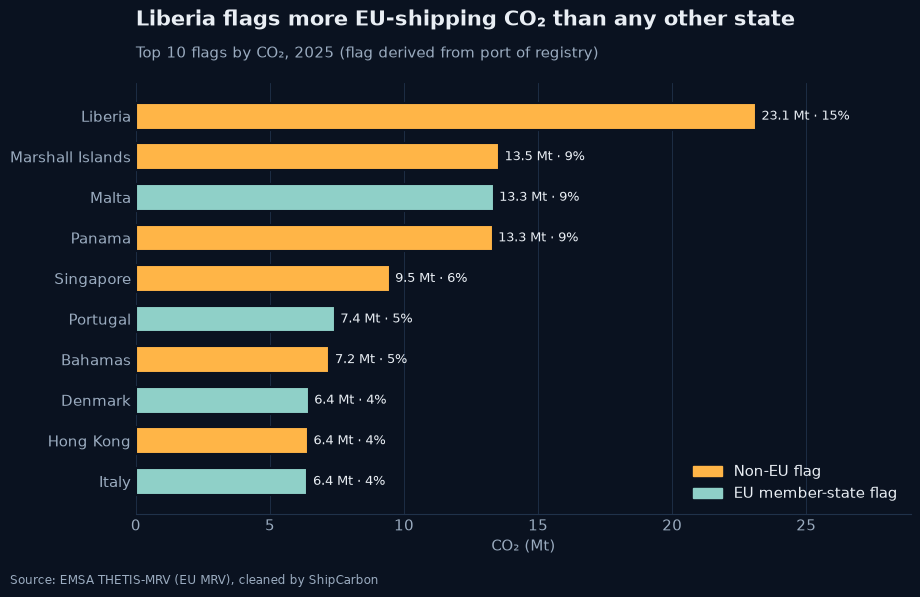

Top 10 flags: 70.0% of CO2
EU member-state flags: 37.0% | Unknown flag: 2.9%


In [5]:
EU = {"Austria", "Belgium", "Bulgaria", "Croatia", "Cyprus", "Czechia", "Denmark", "Estonia", "Finland", "France",
      "Germany", "Greece", "Hungary", "Ireland", "Italy", "Latvia", "Lithuania", "Luxembourg", "Malta", "Netherlands",
      "Poland", "Portugal", "Romania", "Slovakia", "Slovenia", "Spain", "Sweden"}

flags = latest.groupby("flag")["co2_t"].sum().sort_values(ascending=False) / 1e6
total = flags.sum()
top = flags.drop("Unknown", errors="ignore").head(10)[::-1]

fig, ax = plt.subplots(figsize=(10, 5.6))
ax.barh(top.index, top, color=[SEAGLASS if f in EU else AMBER for f in top.index], height=0.66,
        edgecolor=BG, linewidth=1.5)
for name, v in top.items():
    ax.annotate(f"{v:.1f} Mt · {v / total * 100:.0f}%", (v, name), xytext=(4, 0), textcoords="offset points",
                va="center", color=TEXT, fontsize=9.5)
ax.set_xlabel("CO₂ (Mt)")
ax.set_xlim(0, top.max() * 1.25)
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=AMBER, label="Non-EU flag"), Patch(color=SEAGLASS, label="EU member-state flag")],
          loc="lower right")
titles(ax, "Liberia flags more EU-shipping CO₂ than any other state",
       f"Top 10 flags by CO₂, {LATEST} (flag derived from port of registry)")
save(fig, "03_top_flags")

eu_share = flags[flags.index.isin(EU)].sum() / total * 100
print(f"Top 10 flags: {flags.drop('Unknown', errors='ignore').head(10).sum() / total * 100:.1f}% of CO2")
print(f"EU member-state flags: {eu_share:.1f}% | Unknown flag: {flags.get('Unknown', 0) / total * 100:.1f}%")

**Answer.** Liberia (23 Mt), the Marshall Islands, Malta and Panama lead, and the top 10 flags carry 70% of CO₂.
Ships under an EU member-state flag account for only 37% — most CO₂ at EU ports comes from ships registered elsewhere.

## Q4 · How concentrated are emissions?
Ships sorted from largest to smallest emitter; the curve shows what share of all CO₂ the top X% of ships produce.

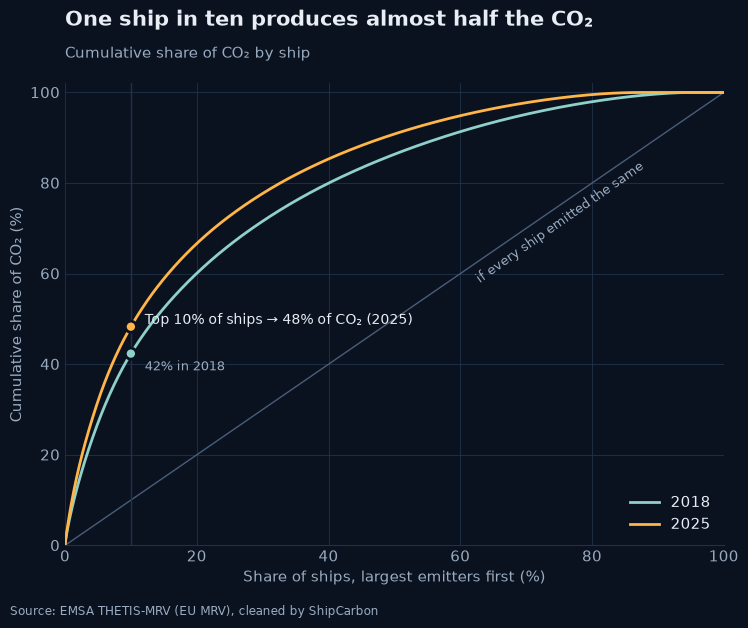

Top  1% of ships: 9.5% of CO2 (2025)
Top 10% of ships: 48.3% of CO2 (2025)
Top 20% of ships: 66.6% of CO2 (2025)
Top 50% of ships: 90.8% of CO2 (2025)


In [6]:
def concentration(co2):
    s = co2.dropna().sort_values(ascending=False)
    return np.arange(1, len(s) + 1) / len(s) * 100, s.cumsum().to_numpy() / s.sum() * 100


def top_share(co2, pct):
    s = co2.dropna().sort_values(ascending=False)
    return s.head(int(len(s) * pct / 100)).sum() / s.sum() * 100


first = int(ship_years["year"].min())
x0, y0 = concentration(ship_years.loc[ship_years["year"] == first, "co2_t"])
x1, y1 = concentration(latest["co2_t"])
s0, s1 = top_share(ship_years.loc[ship_years["year"] == first, "co2_t"], 10), top_share(latest["co2_t"], 10)

fig, ax = plt.subplots(figsize=(8.5, 6))
ax.plot([0, 100], [0, 100], color=DIM, linewidth=1)
ax.annotate("if every ship emitted the same", (62, 58), color=MUTED, fontsize=9, rotation=35)
ax.plot(x0, y0, color=SEAGLASS, linewidth=2, label=str(first))
ax.plot(x1, y1, color=AMBER, linewidth=2, label=str(LATEST))
ax.axvline(10, color=LINE, linewidth=1)
ax.scatter([10, 10], [s0, s1], color=[SEAGLASS, AMBER], s=64, zorder=3, edgecolor=BG, linewidth=2)
ax.annotate(f"Top 10% of ships → {s1:.0f}% of CO₂ ({LATEST})", (10, s1), xytext=(10, 2), textcoords="offset points",
            color=TEXT, fontsize=10)
ax.annotate(f"{s0:.0f}% in {first}", (10, s0), xytext=(10, -12), textcoords="offset points", color=MUTED, fontsize=9.5)
ax.set_xlim(0, 100)
ax.set_ylim(0, 102)
ax.set_xlabel("Share of ships, largest emitters first (%)")
ax.set_ylabel("Cumulative share of CO₂ (%)")
ax.legend(loc="lower right")
titles(ax, "One ship in ten produces almost half the CO₂", "Cumulative share of CO₂ by ship")
save(fig, "04_concentration")

for p in (1, 10, 20, 50):
    print(f"Top {p:>2}% of ships: {top_share(latest['co2_t'], p):.1f}% of CO2 ({LATEST})")

**Answer.** In 2025 the top 10% of ships produced 48% of all CO₂ (the top 1% alone: 9.5%), up from 42% in 2018.
Targeting a small group of large, busy ships would cover a large share of emissions.

## Q5 · Where are emissions produced — between EU ports, on voyages into/out of the EU, or at berth?
Shares of the MRV voyage split. "Into/out of the EU" adds voyages arriving at and departing from EU ports.

Sum of parts / total CO2: {2018: 1.004, 2019: 1.022, 2020: 1.004, 2021: 1.0, 2022: 0.999, 2023: 0.999, 2024: 0.995, 2025: 0.998}


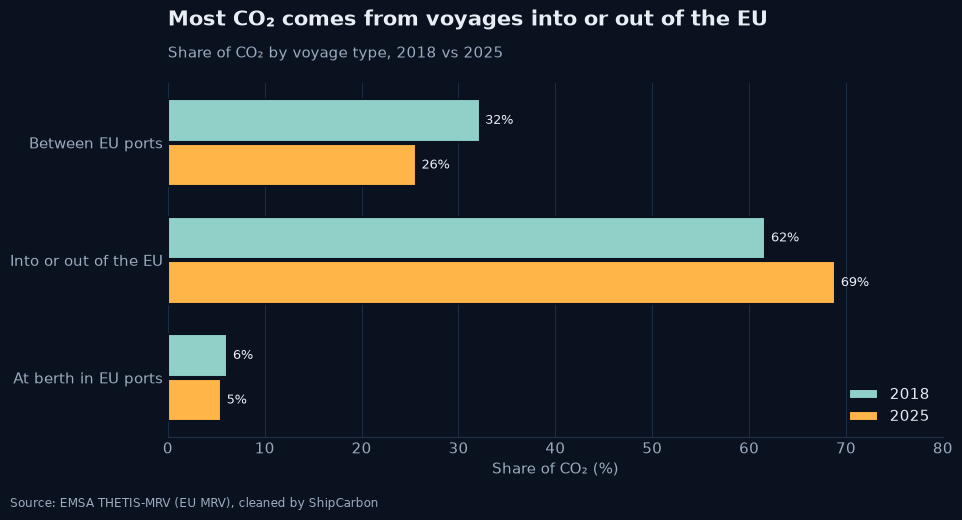

,Between EU ports,Into or out of the EU,At berth in EU ports
year,,,
2018,32.2,61.7,6.1
2019,32.3,60.6,7.1
2020,29.5,64.0,6.5
2021,26.1,67.5,6.3
2022,26.5,67.1,6.4
2023,27.8,65.8,6.4
2024,24.1,70.9,5.0
2025,25.6,68.9,5.5


In [7]:
split = pd.DataFrame({
    "Between EU ports": ship_years.groupby("year")["co2_between_ms_t"].sum(),
    "Into or out of the EU": ship_years.groupby("year")[["co2_from_ms_t", "co2_to_ms_t"]].sum().sum(axis=1),
    "At berth in EU ports": ship_years.groupby("year")["co2_at_berth_t"].sum(),
})
print("Sum of parts / total CO2:", (split.sum(axis=1) / by_year / 1e6).round(3).to_dict())
shares = split.div(split.sum(axis=1), axis=0) * 100

first = int(shares.index.min())
cats = list(shares.columns)[::-1]
pos = np.arange(len(cats))
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.barh(pos + 0.19, shares.loc[first, cats], height=0.36, color=SEAGLASS, edgecolor=BG, linewidth=1.5, label=str(first))
ax.barh(pos - 0.19, shares.loc[LATEST, cats], height=0.36, color=AMBER, edgecolor=BG, linewidth=1.5, label=str(LATEST))
for offset, year in [(0.19, first), (-0.19, LATEST)]:
    for i, cat in enumerate(cats):
        ax.annotate(f"{shares.loc[year, cat]:.0f}%", (shares.loc[year, cat], i + offset), xytext=(4, 0),
                    textcoords="offset points", va="center", color=TEXT, fontsize=9.5)
ax.set_yticks(pos, cats)
ax.set_xlim(0, 80)
ax.set_xlabel("Share of CO₂ (%)")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
titles(ax, "Most CO₂ comes from voyages into or out of the EU",
       f"Share of CO₂ by voyage type, {first} vs {LATEST}")
save(fig, "05_co2_split")

shares.round(1)

**Answer.** Voyages into or out of the EU produce most of the CO₂, and their share grew from 62% (2018) to 69% (2025),
while voyages between EU ports fell from 32% to 26%. Ships at berth in EU ports add only 5–7%.

## Q6 · How efficient is each ship type — CO₂ per nautical mile?
Median and middle 50% of ships per type (types with at least 30 ships, ships with CO₂ > 0).
Caution: per-mile CO₂ favours small ships; a fair efficiency comparison also needs cargo carried.

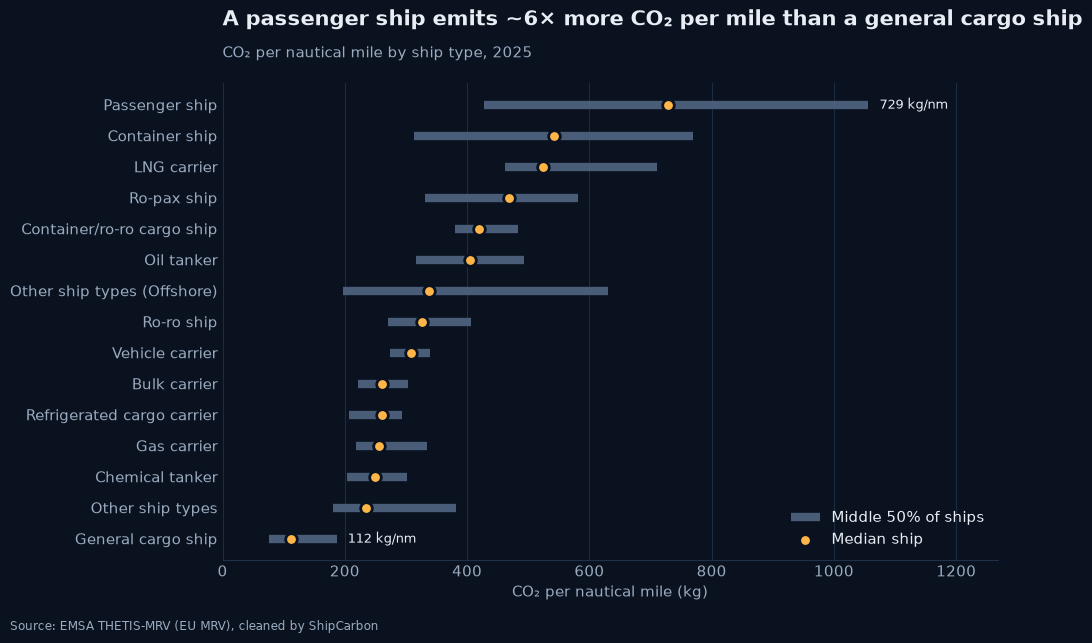

,p25,median,p75
ship_type,,,
General cargo ship,75.0,112.0,187.0
Other ship types,180.0,235.0,381.0
Chemical tanker,203.0,250.0,301.0
Gas carrier,219.0,256.0,334.0
Refrigerated cargo carrier,207.0,261.0,294.0
Bulk carrier,222.0,261.0,303.0
Vehicle carrier,274.0,309.0,339.0
Ro-ro ship,271.0,327.0,407.0
Other ship types (Offshore),197.0,338.0,631.0


In [8]:
eff = latest[(latest["co2_t"] > 0) & (latest["co2_per_nm_kg"] > 0)]
counts = eff.groupby("ship_type").size()
q = eff.groupby("ship_type")["co2_per_nm_kg"].quantile([0.25, 0.5, 0.75]).unstack()
q = q[counts >= 30].sort_values(0.5)

fig, ax = plt.subplots(figsize=(10, 6.2))
ax.hlines(q.index, q[0.25], q[0.75], color=DIM, linewidth=6, label="Middle 50% of ships")
ax.scatter(q[0.5], q.index, color=AMBER, s=70, zorder=3, edgecolor=BG, linewidth=2, label="Median ship")
for name in [q.index[0], q.index[-1]]:
    ax.annotate(f"{q.loc[name, 0.5]:.0f} kg/nm", (q.loc[name, 0.75], name), xytext=(8, 0), textcoords="offset points",
                va="center", color=TEXT, fontsize=9.5)
ax.set_xlabel("CO₂ per nautical mile (kg)")
ax.set_xlim(0, q[0.75].max() * 1.2)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
titles(ax, "A passenger ship emits ~6× more CO₂ per mile than a general cargo ship",
       f"CO₂ per nautical mile by ship type, {LATEST}")
save(fig, "06_co2_per_nm")

q.round(0).rename(columns={0.25: "p25", 0.5: "median", 0.75: "p75"})

**Answer.** Passenger ships (median 729 kg CO₂/nm), container ships (542) and LNG carriers (524) burn the most per mile;
general cargo ships (112) the least. Per-mile figures mostly reflect ship size and speed — they say nothing about how
much cargo is moved, so they are not a ranking of "clean" vs "dirty" ship types.

## Q7 · LNG carriers: how much methane (CH₄) and nitrous oxide (N₂O) since 2024?
Since 2024 MRV reports CH₄ and N₂O. CO₂eq converts them with global-warming factors; the fit below recovers the
factors EMSA used.

Implied global-warming factors: CH4 = 28, N2O = 265
LNG carriers' share of all methane: {2024: 62.4, 2025: 58.7}


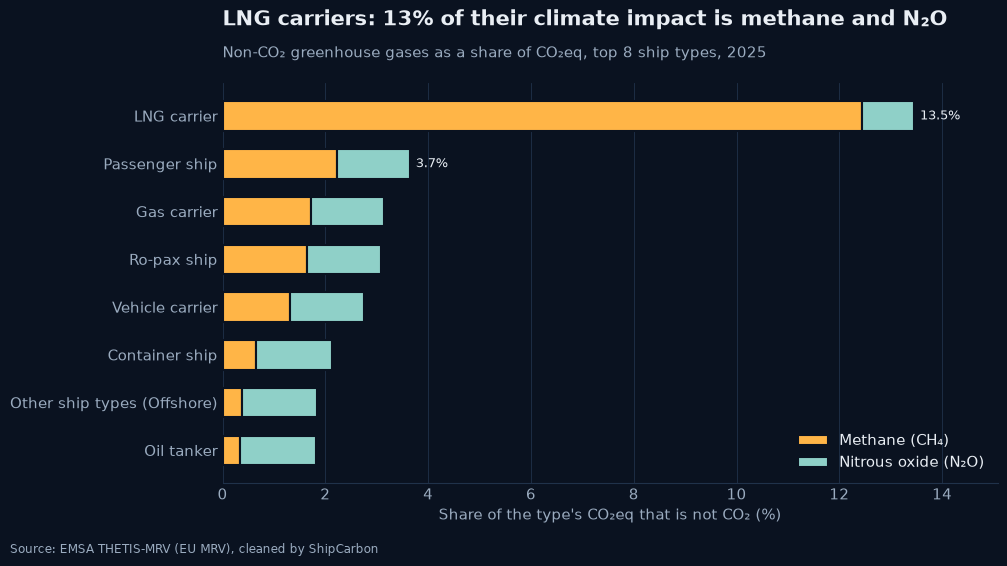

ships     ch4_t    n2o_t  co2_Mt  co2eq_Mt  \
year LNG carrier                                               
2024 False        14105  24696.81  7976.73  139.88    142.68   
     True           361  40950.27   368.52    8.37      9.61   
2025 False        17428  35531.33  8094.33  142.63    145.77   
     True           414  50520.69   438.80    9.84     11.37   

                  non_CO2_share_of_CO2eq_%  
year LNG carrier                            
2024 False                            1.97  
     True                            12.94  
2025 False                            2.15  
     True                            13.46

In [9]:
g = ship_years[ship_years["year"] >= 2024].dropna(subset=["ch4_t", "n2o_t", "co2eq_t"]).copy()
gwp, *_ = np.linalg.lstsq(g[["ch4_t", "n2o_t"]].to_numpy(), (g["co2eq_t"] - g["co2_t"]).to_numpy(), rcond=None)
GWP_CH4, GWP_N2O = np.round(gwp)
print(f"Implied global-warming factors: CH4 = {GWP_CH4:.0f}, N2O = {GWP_N2O:.0f}")

is_lng = g["ship_type"] == "LNG carrier"
summary = g.groupby(["year", is_lng.rename("LNG carrier")]).agg(
    ships=("imo", "size"), ch4_t=("ch4_t", "sum"), n2o_t=("n2o_t", "sum"),
    co2_Mt=("co2_t", lambda s: s.sum() / 1e6), co2eq_Mt=("co2eq_t", lambda s: s.sum() / 1e6))
summary["non_CO2_share_of_CO2eq_%"] = (1 - summary["co2_Mt"] / summary["co2eq_Mt"]) * 100
ch4_share = g[is_lng].groupby("year")["ch4_t"].sum() / g.groupby("year")["ch4_t"].sum() * 100
print("LNG carriers' share of all methane:", ch4_share.round(1).to_dict())

y = g[g["year"] == LATEST]
by_type = y.groupby("ship_type")[["ch4_t", "n2o_t", "co2eq_t"]].sum()
by_type["CH₄"] = by_type["ch4_t"] * GWP_CH4 / by_type["co2eq_t"] * 100
by_type["N₂O"] = by_type["n2o_t"] * GWP_N2O / by_type["co2eq_t"] * 100
top = by_type.assign(total=by_type["CH₄"] + by_type["N₂O"]).nlargest(8, "total")[::-1]

fig, ax = plt.subplots(figsize=(10, 5.2))
ax.barh(top.index, top["CH₄"], color=AMBER, height=0.62, edgecolor=BG, linewidth=1.5, label="Methane (CH₄)")
ax.barh(top.index, top["N₂O"], left=top["CH₄"], color=SEAGLASS, height=0.62, edgecolor=BG, linewidth=1.5,
        label="Nitrous oxide (N₂O)")
for name in top.index[-2:]:
    ax.annotate(f"{top.loc[name, 'total']:.1f}%", (top.loc[name, "total"], name), xytext=(4, 0),
                textcoords="offset points", va="center", color=TEXT, fontsize=9.5)
ax.set_xlabel("Share of the type's CO₂eq that is not CO₂ (%)")
ax.set_xlim(0, top["total"].max() * 1.12)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
titles(ax, "LNG carriers: 13% of their climate impact is methane and N₂O",
       f"Non-CO₂ greenhouse gases as a share of CO₂eq, top 8 ship types, {LATEST}")
save(fig, "07_lng_methane")

summary.round(2)

**Answer.** LNG carriers are about 2% of ships but emit ~60% of all reported methane (50,500 t CH₄ in 2025), mostly
unburned gas ("methane slip"). Methane and N₂O make up about 13% of their CO₂eq, versus about 2% for the rest of the
fleet. EMSA uses the IPCC factors 28 (CH₄) and 265 (N₂O).

## Wrap-up
The short, shareable version of these findings is in [`docs/insights.md`](../docs/insights.md).
Next phase (Phase 4) uses `ship_years.csv` to predict annual fuel consumption.